# In-class Assignment: Graph Theory and Cell Towers
# Day 11
# CMSE 202

In this assignment you will work with your group to develop a program to use a color graphing algorithm to select frequencies for cell towers around MSU.  There are four major parts to this assignment.  Try to make sure you get through all of it, but don't stress too much if you don't finish.

## Learning goals for today

By the end of today's class, you should be able to:

1. Implement a k-nearest-neighbor (KNN) graph algorithm for a set of points.
1. Build and manipulate graphs with `networkx` (construct, draw, and color them).
1. Apply a greedy graph-coloring algorithm to assign non-conflicting frequencies.
1. Visualize geographic data by plotting the towers (and their assigned colors) on a map.
1. Test your own code and reason about whether it behaves correctly.

### How this connects to the course learning goals

Beyond today's specific goals above, this assignment builds toward these **course-level learning goals** (see the syllabus, or the Day 1 notebook, for the full CLG 1-7 list):

- **CLG 3 - Use appropriate data types, data structures, and algorithms:** you'll implement the KNN graph algorithm and work with graphs, adjacency structures, and greedy coloring.
- **CLG 1 - Design and write programs to solve problems:** you'll write (and test) your own KNN function.
- **CLG 2 - Identify and use pre-existing tools and code:** you'll use `networkx` for graphs/coloring and a mapping package (e.g. `folium`) for the map.
- **CLG 5 - Manipulate, analyze, and visualize datasets:** you'll visualize the tower network and plot the colored towers on a real map.
- **CLG 6 - Work in diverse groups:** you'll tackle the KNN problem and the frequency-assignment task together with your group.

### Agenda for today's class:

1. [Part 1: Download and import the data](#p1)
2. [Part 2: K-nearest neighbor graph](#p2)
3. [Part 3: Greedy graph coloring](#p3)
4. [Part 4: Plotting towers and their colors on a map](#p4)

### <p style="text-align: right;"> &#9989; Dhruti Bhat </p>
#### <p style="text-align: right;"> &#9989; Ethan, Daniel, Brook</p>

---
# Problem Statement

**As was presented in the pre-class assignment**, the signals from different cellphone towers that are close together can interfere.  

<img src="https://raw.githubusercontent.com/msu-cmse-courses/cmse202-supplemental-data/refs/heads/main/images/cell_tower_interference.jpg" width="500px" alt="Two overlapping circles labeled Radio Station 1 Range and Radio Station 2 Range, each with a tower icon, with a red X where the ranges overlap -- illustrating interference when nearby towers share a frequency."><p style="text-align: right;">From: http://www.onlivespot.com/2011/08/dido-wireless-technology-explained.html</p>

In order to avoid this overlap cell phone companies use different frequency ranges in the Electromagnetic spectrum.  Two towers that are close together but have differences in frequencies (shown as colors, red/green/black in the following figure) do not cause nearly as much interference. 

<img src="https://raw.githubusercontent.com/msu-cmse-courses/cmse202-supplemental-data/refs/heads/main/images/cell_tower_frequencies.jpg" width="500px" alt="Six cell-tower coverage circles colored red, green, and blue; neighboring towers use different colors (frequencies) so their overlapping ranges do not interfere."><p style="text-align: right;">From:  http://www.onlivespot.com/2011/08/dido-wireless-technology-explained.html</p>

However, cellphone towers are never distributed in such an even pattern.   Consider the following map which shows the location of cell towers around Michigan State.

<img src="https://raw.githubusercontent.com/msu-cmse-courses/cmse202-supplemental-data/refs/heads/main/images/MSU_Towers.png" width="500px" alt="A map of the Lansing and East Lansing area around Michigan State University dotted with many cell-tower markers, showing their uneven real-world distribution.">
<p style="text-align: right;">From: http://www.antennasearch.com/</p>

Another problem is that cellphone companies have to pay for each frequency range they use.  So they would like to minimize the number of frequencies that they need to purchase while also minimizing the interference between the cell towers. 

In this assignment you are going to work as a group to solve this problem using graph coloring.

---
<a id="p1"></a>
## Part 1: Download and import the data

We will be using antenna data from the following website:

http://www.antennasearch.com/

**&#9989;  Do This:** We previously downloaded a CSV file from this website for all of the **towers** in a 3 Mile radius from the MSU engineering building (428 S Shaw Lane, East Lansing, MI 48824). **You can download this file from here:**

`https://raw.githubusercontent.com/msu-cmse-courses/cmse202-supplemental-data/main/data/TowersYYH730463QHM18572.csv`

Make sure that the downloaded file is in the same directory as your in-class notebook.

**Optional**: Feel free to try running the same search and take a look at just the **towers**. When you start to visualize the data in the file we've shared you can see if any new towers have been added since the data was last pulled.

Finally, **write code** to load the file into Python and generate a list of longitude and latitude for the towers.

In [17]:
# Put your function here!
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
!curl -O https://raw.githubusercontent.com/msu-cmse-courses/cmse202-supplemental-data/main/data/TowersYYH730463QHM18572.csv
points = towers[["longitude", "latitude"]].to_numpy()
print(towers.columns)
print(towers[["longitude", "latitude"]])

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 10526  100 10526    0     0   243k      0 --:--:-- --:--:-- --:--:--  250k
Index(['tower_type', 'faa_study_number', 'registration_number', 'latitude',
       'longitude', 'status_code', 'date_constructed',
       'structure_street_address', 'structure_city', 'structure_state_code',
       'height_of_structure', 'ground_elevation',
       'overall_height_above_ground', 'overall_height_amsl', 'structure_type',
       'owner_entity_name', 'owner_licensee_id', 'owner_first_name',
       'owner_last_name', 'owner_phone', 'owner_internet_address',
       'owner_street_address', 'owner_po_box', 'owner_city', 'owner_state',
       'owner_zip_code', 'owner_attention', 'rep_entity_name',
       'rep_licensee_id', 'rep_first_name', 'rep_last_name', 'rep_phone',
       'rep_internet_address', 'rep_street_address', 'rep_po_box', 'rep_city'

**&#9989;  Do This:** Generate a plot similar to the following showing the towers on the x-y plane.

<img src="https://raw.githubusercontent.com/msu-cmse-courses/cmse202-supplemental-data/refs/heads/main/images/tower_graph.png" alt="A matplotlib scatter plot titled 'example tower locations' showing cell-tower positions as points on a longitude versus latitude plane with equal axis scaling.">


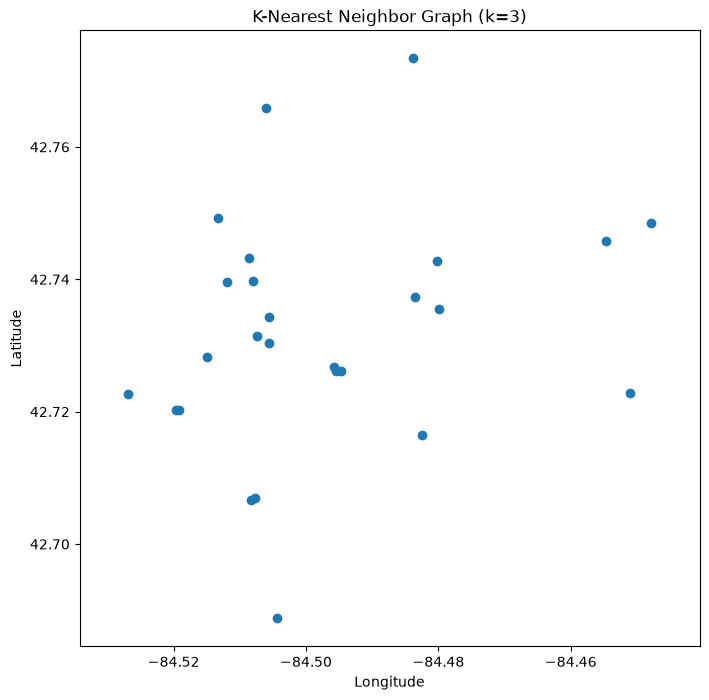

In [18]:
# Put your plotting code here.
plt.figure(figsize=(8, 8))
plt.scatter(points[:, 0], points[:, 1])
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("K-Nearest Neighbor Graph (k=3)")
plt.axis("equal")
plt.show()

&#9989; **Question 1**: By default `matplotlib.pyplot.scatter` will scale the x-axis and y-axes to best fit the points. However, sometimes (as is the case here) we want the scaling of both axes to be equal.  What command can you use for the above plot to ensure that the distances are the same in the x-direction as the y-direction?

<font size=+3>&#9998;</font> Do This - Erase the contents of this cell and replace it with your answer to the above question!  (double-click on this text to edit this cell, and hit shift+enter to save the text)

---
<a id="p2"></a>
## Part 2: Generating a K-Nearest Neighbor Graph

In the pre-class assignment, you were asked to try and write an algorithm that found the nearest neighbor for every point in a collection of points. There's not necessarily one right way to solve this problem, so your solution might have looked quite a bit different this (or perhaps you didn't quite get things working), but here's one possible solution:

In [19]:
# Possible solution for the nearest-neighbor algorithm
import math
def distance(p1,p2):
    '''Returns the distance betwen two numpy points'''
    return math.sqrt((p1[0] - p2[0])**2 + (p1[1] - p2[1])**2)
    
def nearest_neighbors(points):
    '''Generates an adjacency list based on the Nearest neighbor graph algorithm.'''
    G = dict()
    for p in range(0,len(points)):
        min_distance = np.inf
        min_point = -1
        for n in range(0,len(points)):
            if p != n:
                d = distance(points[p], points[n])
                if d < min_distance:
                    min_distance = d
                    min_point = n
        if min_point == -1:
            print("ERROR-point not found")
        G[p] = [min_point]
    return G

**But what if we wanted to find the nearest *2* neighbors? The nearest 3? More?**

**&#9989;  Do This:** Next **write a function that generates a graph using the k-nearest neighbor graph algorithm**.  More information about the nearest neighbor and k-nearnest neighbor algorithm can be found here:

https://en.wikipedia.org/wiki/Nearest_neighbor_graph

The KNN graph is very similar to the nearest neighbor graph you did in the pre-class assignment. However, now instead of only finding the closest point to each point you find the k-closest points.

So that you can check your work with the **provided test cell that follows**, your function should:
- be named **`KNN`** and take two arguments -- **`KNN(k, points)`** -- where `k` is the number of neighbors to find and `points` is the array of points;
- **return an adjacency list as a dictionary** (just like the `nearest_neighbors` function from the pre-class, but with `k` neighbors per point): each key is a point's index, and its value is a **list of the indices of that point's `k` nearest neighbors**.

**Important note**: While the nearest-neighbor and KNN problems are similar, the same approach may not work well for both solutions! You should think this through and talk about it with your group. **How will you tackle this problem?**

**&#9989; Do This -- plan it out as a group first (before you write any code):** Grab a whiteboard (or a piece of paper) and work through the algorithm together with your group:

1. Sketch a small set of points (5 or 6 is plenty).
2. Pick a small value of `k` (for example, **`k = 2`**) and, **by hand**, find the `k` nearest neighbors for one or two of your points.
3. Talk through the steps you took: How did you measure the distance between points? How did you keep track of which points were closest? How would you store the result as an adjacency list (the dictionary described above)?

Once your group agrees on the logic, translating it into the `KNN` function below will be much easier -- and easier to debug if something goes wrong!

In [26]:
# Put your k-nn function here.
# Reminder: name it KNN(k, points) and return the adjacency-list dictionary
# described above, so the provided test cell can check it.
def KNN(k, points):
    G = {}

    for i in range(len(points)):
        distances = []

        for j in range(len(points)):
            if i != j:
                d = distance(points[i], points[j])
                distances.append((d, j))

        distances.sort()
        G[i] = [j for d, j in distances[:k]]

    return G

**&#9989; Do This:** To test whether your KNN function is working as intended, run the following cell. It assumes you named your function `KNN(k, points)` and that it returns an adjacency list as a **dictionary** -- each key is a point's index, and its value is a list of that point's `k` nearest-neighbor indices. **If all the tests pass, you should have a functional KNN solution!** If a test fails, read the message -- it will tell you which point and which value of `k` had a problem.

In [21]:
# DO NOT MODIFY THIS CELL -- run it to check your KNN function.
#
# This test assumes your function is named `KNN(k, points)` and returns an
# adjacency list as a dictionary: each key is a point's index (0, 1, 2, ...) and
# its value is a list (or array) of that point's k nearest-neighbor indices.
import numpy as np

def _knn_self_test(knn_func):
    pts = np.array([[0.0, 0.0], [0.2, 0.1], [0.9, 0.8],
                    [1.0, 1.0], [0.5, 0.5], [0.1, 0.9]])
    n = len(pts)
    for k in (1, 2, 3):
        G = knn_func(k, pts)
        assert G is not None, "your KNN function returned None"
        assert len(G) == n, f"expected one entry per point ({n}), got {len(G)}"
        for i in range(n):
            nbrs = list(G[i])
            dist = {j: float(np.hypot(pts[i, 0] - pts[j, 0], pts[i, 1] - pts[j, 1]))
                    for j in range(n) if j != i}
            assert len(nbrs) == k, f"point {i} (k={k}): expected {k} neighbors, got {len(nbrs)}"
            assert i not in nbrs, f"point {i}: a point should not be its own neighbor"
            assert len(set(nbrs)) == k, f"point {i} (k={k}): the neighbors should be distinct"
            # the chosen neighbors must be the k closest (their distances match the k smallest)
            chosen = sorted(dist[j] for j in nbrs)
            k_smallest = sorted(dist.values())[:k]
            assert np.allclose(chosen, k_smallest), \
                f"point {i} (k={k}): neighbors {nbrs} are not the {k} nearest points"
    print("All tests passed! Your KNN function returns the correct k nearest neighbors.")

_knn_self_test(KNN)


All tests passed! Your KNN function returns the correct k nearest neighbors.


It's always important to test your code! The automated check above runs your `KNN` function on a known set of points -- including the important case where **`k=1`**, which should reproduce the nearest-neighbor graph you built in the pre-class.

**Optional:** if you'd like, use the cell below to experiment further -- try your function on different inputs and values of `k` and confirm it behaves the way you expect.

In [ ]:
# (Optional) Experiment with your own tests here


**&#9989; Do This:** Using the tower locations from Part 1, generate a figure similar to the following:

<img src="https://raw.githubusercontent.com/msu-cmse-courses/cmse202-supplemental-data/refs/heads/main/images/knn_graph.png" alt="A matplotlib plot titled 'example k-nearest neighbor (k=3) graph on tower locations' showing the tower points connected by line segments to each point's three nearest neighbors.">  

While the above graph displays the network, clearly not a lot of attention was given to the aesthetics!

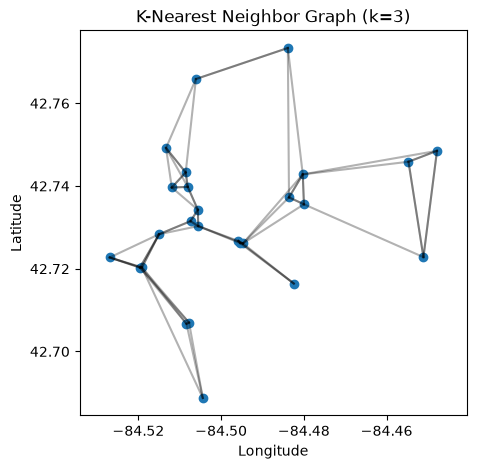

In [24]:
# Put the code that makes your cell tower plot here
G = KNN(3, points)

plt.figure(figsize=(5, 5))

for i in G:
    for j in G[i]:
        plt.plot([points[i, 0], points[j, 0]], [points[i, 1], points[j, 1]],"k-", alpha=0.3)
plt.scatter(points[:, 0], points[:, 1])
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("K-Nearest Neighbor Graph (k=3)")
plt.axis("equal")
plt.show()

---
<a id="p3"></a>
## Part 3: Greedy Graph Coloring

Next we will run a greedy graph coloring algorithm on your K-NN graph with k = 3 and plot the towers in the x-y plane colored to match the frequency selected. For example:

<img src="https://raw.githubusercontent.com/msu-cmse-courses/cmse202-supplemental-data/refs/heads/main/images/knn_color_graph.png" alt="A matplotlib plot of the tower locations with each tower node colored by a greedy graph coloring, so neighboring towers in the k=3 KNN graph receive different colors.">

**&#9989; Do This:** Using networkx, apply the "greedy" graph coloring algorithm to the K-NN graph (K=3) developed in part 2 of the tower data downloaded in part 1.  

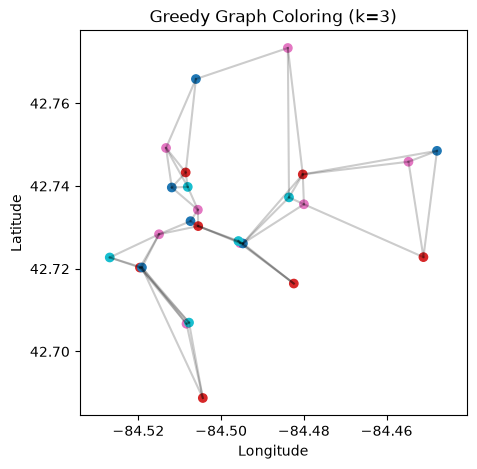

Number of colors used: 4


In [32]:
# Plot your colored cell tower graph here.
import networkx as nx
G = KNN(3, points)

graph = nx.Graph()
graph.add_nodes_from(range(len(points)))

for i in G:
    for j in G[i]:
        graph.add_edge(i, j)

colors = nx.coloring.greedy_color(graph, strategy="largest_first")
tower_colors = [colors[i] for i in range(len(points))]
plt.figure(figsize=(5, 5))
for i, j in graph.edges():
    plt.plot([points[i, 0], points[j, 0]], [points[i, 1], points[j, 1]],"k-", alpha=0.2)

plt.scatter(points[:, 0],points[:, 1],c=tower_colors,cmap="tab10")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Greedy Graph Coloring (k=3)")
plt.axis("equal")
plt.show()

print("Number of colors used:", len(set(tower_colors)))

---
<a id="p4"></a>
## Part 4: Plot tower colors on a map
Finally plot the towers on a map and set the marker colors to your individual frequency colors. Something like the following:

<img src="https://raw.githubusercontent.com/msu-cmse-courses/cmse202-supplemental-data/refs/heads/main/images/knn_tower_map_example.png" width="800px" alt="A street map of the Lansing and East Lansing area with cell-tower locations shown as colored map pins (green, red, blue, and purple), where the colors represent the different frequencies assigned by the graph-coloring algorithm.">

**Note**: In order to overlay the tower locations as points on map, you'll like need to find a python package that can help you do this. We explored some such options in a previous class period!

**&#9989; Do This:** First, write some test code to generate a map with colored points using whatever package you chose to use.

In [30]:
#Put your test code here
import folium
center_lat = np.mean(points[:, 1])
center_lon = np.mean(points[:, 0])
test_map = folium.Map(location=[center_lat, center_lon],zoom_start=13)
folium.CircleMarker(location=[points[0, 1], points[0, 0]],radius=6,color="red",fill=True,fill_color="red").add_to(test_map)
test_map

**&#9989; Do This:** Finally, put it all together.  Generate a map with markers colored based on the frequencies selected in the graph coloring algorithm in part 3.  Use the K-NN graph with ```k=3``` generated from part 2 of the tower data downloaded from part 1. 

In [31]:
# Put your map code here
# Create a map centered on the tower locations
tower_map = folium.Map(location=[center_lat, center_lon],zoom_start=13)
palette = ["red", "blue", "green", "purple", "orange","darkred", "lightblue", "darkgreen", "pink","cadetblue", "darkpurple", "beige"]
num_colors = len(set(tower_colors))
for i in range(len(points)):
    frequency_color = palette[tower_colors[i] % len(palette)]

    folium.CircleMarker(location=[points[i, 1], points[i, 0]],radius=5,color=frequency_color,fill=True,fill_color=frequency_color,
                        fill_opacity=0.8,popup=f"Tower {i}: Frequency {tower_colors[i]}").add_to(tower_map)

tower_map

----

-----
### Congratulations, we're done!

Now, you just need to submit this assignment by uploading it to the course <a href="https://d2l.msu.edu/">Desire2Learn</a> web page for today's submission folder (Don't forget to add your name in the first cell).

&#169; Copyright 2026,  Department of Computational Mathematics, Science and Engineering at Michigan State University